你问到点子上了。前面全在赶路，没停下来说过整件事的逻辑。**我先讲清楚整个项目在论证什么，再回头看你每一步在这个论证里的位置。**

---

## 一句话说清：这个项目要证明什么

> **当某个输出的数据很稀缺时，借用其他相关输出的数据，能预测得更准。**

这就是 MOGP 相对"每个输出各建一个独立 GP"的全部价值。你的报告从头到尾就是在验证这一句话。

**打个比方**：你要估算某个学生的数学成绩，但他只考过 3 次数学。如果你知道他物理和化学各考过 30 次，而且数学-物理-化学成绩之间有相关性，那你用三科一起建模，会比只看那 3 次数学准。MOGP 就是这件事的数学版本。

---

## 要让这个论证成立，必须先满足三个前提

| 前提 | 为什么必须 | 你哪一步在验证它 |
|---|---|---|
| A. 输出之间**真的相关** | 不相关就没有"力"可借 | ✅ EDA 相关性矩阵 |
| B. 存在**数据稀缺的输出** | 都数据充足的话，借不借力无所谓 | ⬜ 下一步要构造 |
| C. 有**能对比的基线** | 不跟独立 GP 比，说不出"好多少" | ⬜ 建模阶段 |

---

你走到现在，做的每一步都在这条链上：## 三个你现在最可能困惑的点

**1. "为什么要自己把数据藏起来？"——这是全项目最反直觉的一步**

Jura 的 359 个点，三种金属其实**都测全了**。我们却要人为把 Cd 的 100 个值藏起来假装没测过。

原因：**这是唯一能"验分"的办法**。藏起来的那 100 个真值，就是标准答案。模型预测完这 100 个位置的 Cd，跟真值一比，就得到 RMSE。如果不藏，模型预测的地方你没有真值，永远不知道它准不准。

而且现实里这个场景是真的：Cd 检测成本高，实际项目中确实经常只测部分点位。所以这不是造假，是**模拟真实的采样约束**。

**2. "EDA 那三个 0.65/0.69/0.70 到底为什么重要？"**

它是**前提 A 的证据**。如果这个数字接近 0，说明 Ni/Zn 对预测 Cd 毫无帮助——那你后面做什么都是白费，MOGP 必然打不过独立 GP。

**这是一个 go / no-go 检查点**。跑出这个数字之前，整个项目是有可能死掉的；跑出来之后，你才知道后面值得投入。这就是为什么我坚持先做 EDA 再建模。

**3. "log 变换那一步是干嘛的？"**

GP 假设噪声是高斯的（对称的钟形）。原始 Cd 浓度是右偏的长尾分布，直接喂进去，模型会在高浓度区域给出错误的不确定性估计。log 之后变成对称钟形，假设就成立了。

**这属于"让模型的假设与数据匹配"的常规操作**，不是 MOGP 特有的，但漏掉会让后面所有结果都不可信。

---

## 一个你可能没意识到的落差

你问"我到底做了什么"，说明**前面的对话是任务驱动的，不是理解驱动的**——我给一步你做一步，但没建立整体框架。这会有一个具体后果：

**到了阶段 8 写报告时，你要写的是"为什么这么设计实验"，而不是"我跑了哪些代码"**。如果现在的理解停留在操作层面，那时候会写不出东西——因为报告里最值钱的部分恰恰是上面这条论证链，不是代码。

**建议**：把上面那张图和"要证明什么"那一句话，现在就写进 `results/experiment_log.md` 的开头。后面每做一步，问自己一句"这一步在这条链上的哪个位置"。这样到写报告时，方法论述那一节基本是现成的。

---

理解上还有哪里卡着？或者可以继续往第 4 步走了。

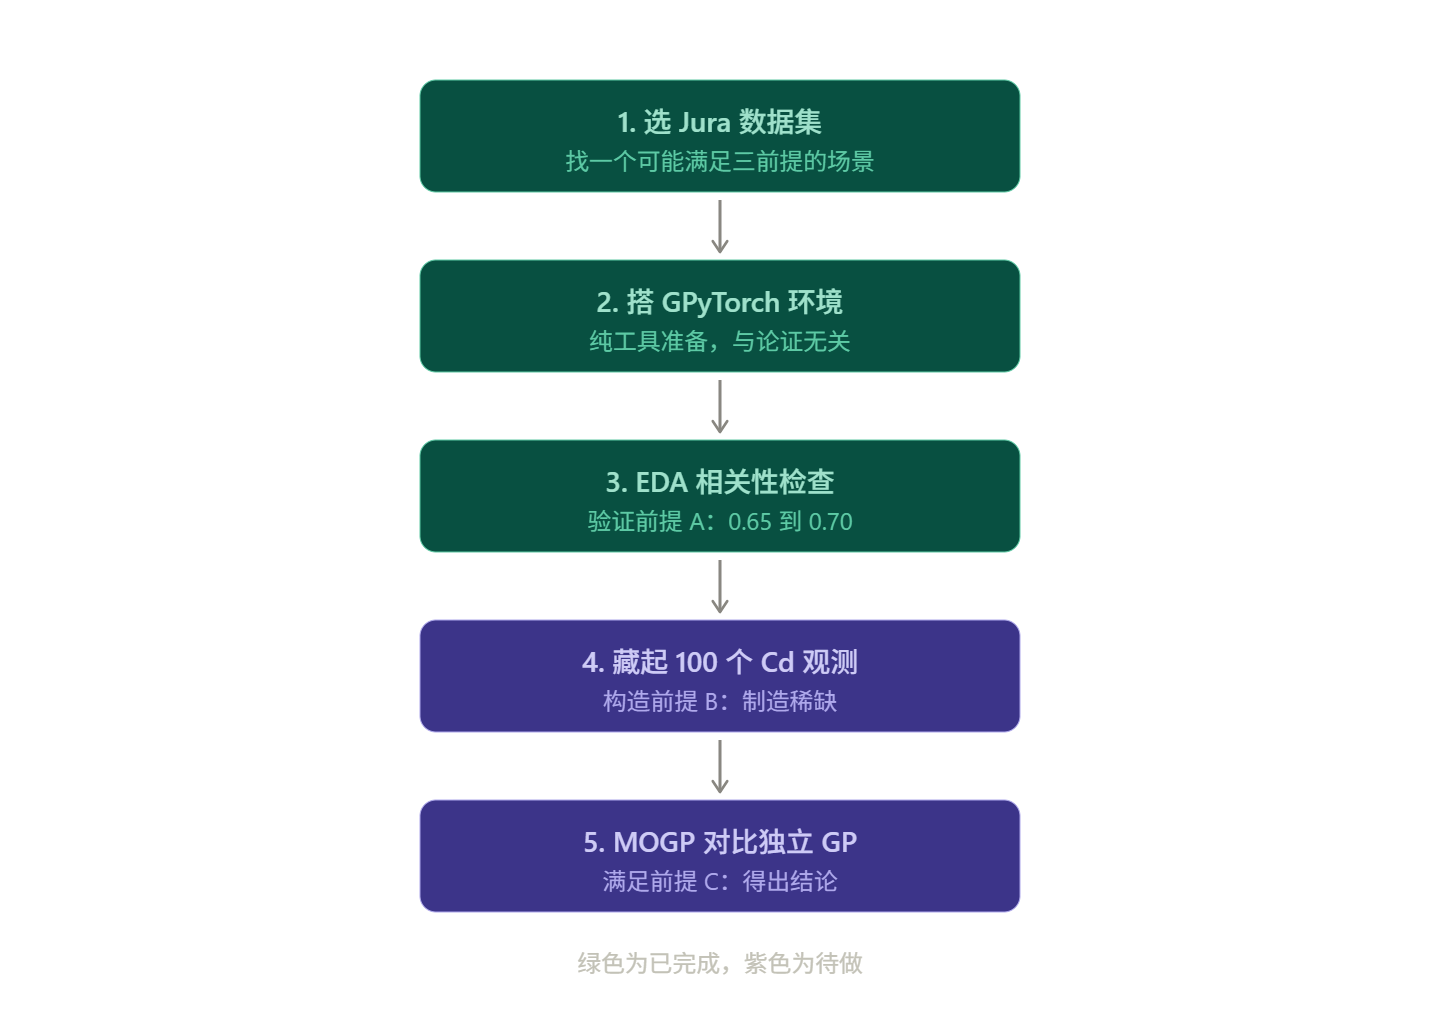